# Tarea 2: Estadística descriptiva en Python

**Estadística I**

**Universidad Industrial de Santander**

Este cuaderno analiza las variables EDAD_PADRE y N_EMB de la base de nacimientos del DANE 2024.


In [62]:
# =====================================================
# 1. IMPORTAR LIBRERÍAS
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler

from scipy.stats import (
    pearsonr,
    spearmanr,
    kendalltau
)
from scipy.stats import skew, kurtosis

Se importan las librerías necesarias para cargar, analizar y representar gráficamente los datos.

In [25]:
import pandas as pd
import io
from google.colab import files
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler

from scipy.stats import (
    pearsonr,
    spearmanr,
    kendalltau
)

uploaded = files.upload()


nombre_archivo = list(uploaded.keys())[0]

io_csv = io.BytesIO(uploaded[nombre_archivo])

tabla = pd.read_csv(
    io_csv,
    sep=",",
    index_col=0,
    encoding="latin-1"
)


tabla.head(3)

Saving BD-EEVV-Nacimientos-2024.csv to BD-EEVV-Nacimientos-2024 (6).csv


,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1


Se carga la base de datos de nacimientos del DANE desde Google Colab y se muestran sus tres primeras filas.

In [80]:
datos = datos[
    (datos['EDAD_PADRE'] > 0) &
    (datos['EDAD_PADRE'] < 120) &
    (datos['N_EMB'] > 0) &
    (datos['N_EMB'] < 99)
]

Se conservan únicamente las edades y cantidades de embarazos dentro de rangos válidos.

In [81]:
for variable in ['EDAD_PADRE', 'N_EMB']:

    print('\nVariable:', variable)
    print('Media:', datos[variable].mean())
    print('Mediana:', datos[variable].median())
    print('Moda:', datos[variable].mode().tolist())
    print('Varianza:', datos[variable].var())
    print('Desviación estándar:', datos[variable].std())
    print('Asimetría:', skew(datos[variable]))
    print(
        'Curtosis:',
        kurtosis(datos[variable], fisher=False)
    )


Variable: EDAD_PADRE
Media: 30.399666949841926
Mediana: 30.0
Moda: [30]
Varianza: 59.42525704580291
Desviación estándar: 7.70877792168142
Asimetría: 0.7422600985923384
Curtosis: 3.860755569999743

Variable: N_EMB
Media: 2.0416177494552445
Mediana: 2.0
Moda: [1]
Varianza: 1.6579588841839075
Desviación estándar: 1.2876175224747088
Asimetría: 1.9966262790249505
Curtosis: 9.605849499993035


Se calculan las principales medidas descriptivas de EDAD_PADRE y N_EMB para resumir su comportamiento.

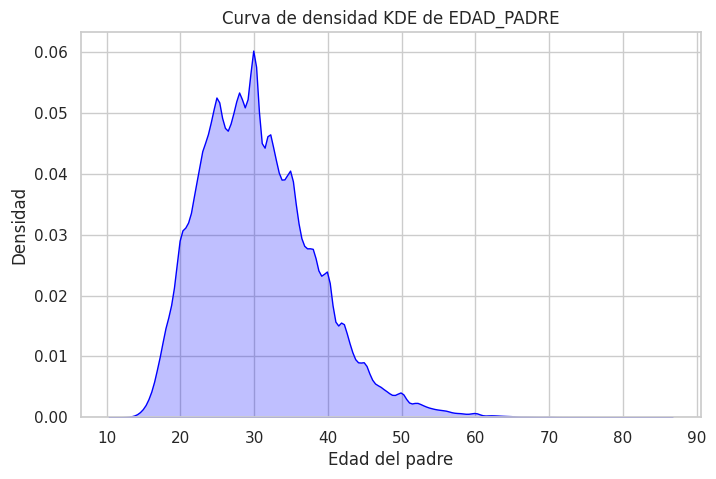

In [107]:
# =====================================================
# CURVA DE DENSIDAD KDE PARA EDAD_PADRE
# =====================================================

plt.figure(figsize=(8, 5))

sns.kdeplot(
    datos['EDAD_PADRE'],
    fill=True,
    color='blue'
)

plt.title('Curva de densidad KDE de EDAD_PADRE')
plt.xlabel('Edad del padre')
plt.ylabel('Densidad')
plt.show()

Se genera la curva KDE para observar la distribución y concentración de las edades de los padres.

In [59]:
# Importar Seaborn
import seaborn as sns

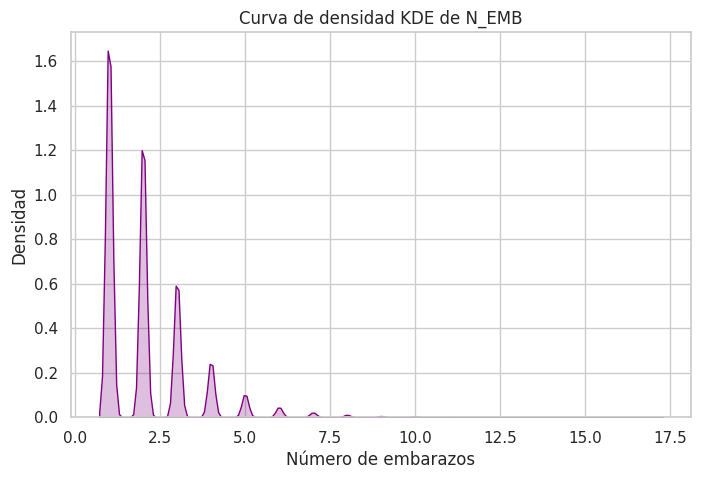

In [108]:
# =====================================================
# CURVA DE DENSIDAD KDE PARA N_EMB
# =====================================================

plt.figure(figsize=(8, 5))

sns.kdeplot(
    datos['N_EMB'],
    fill=True,
    color='purple'
)

plt.title('Curva de densidad KDE de N_EMB')
plt.xlabel('Número de embarazos')
plt.ylabel('Densidad')
plt.show()

Se genera la curva KDE para observar la distribución y concentración del número de embarazos.

In [32]:
datos = datos.dropna()

In [66]:
# =====================================================
# 2. SELECCIONAR LAS VARIABLES
# =====================================================

# Variable independiente
columna_x = "N_EMB"

# Variable dependiente
columna_y = "EDAD_PADRE"

df_bivariado = datos[
    [columna_x, columna_y]
].copy()

# Convertir los datos a valores numéricos
df_bivariado[columna_x] = pd.to_numeric(
    df_bivariado[columna_x],
    errors="coerce"
)

df_bivariado[columna_y] = pd.to_numeric(
    df_bivariado[columna_y],
    errors="coerce"
)

# Eliminar filas con datos faltantes
df_bivariado = df_bivariado.dropna()

# Eliminar valores no válidos
df_bivariado = df_bivariado[
    (df_bivariado[columna_x] > 0) &
    (df_bivariado[columna_x] < 99) &
    (df_bivariado[columna_y] > 0) &
    (df_bivariado[columna_y] < 100)
]

df_bivariado.head()

,N_EMB,EDAD_PADRE
COD_DPTO,,
76,2,39
19,3,27
41,3,28
50,1,27
50,5,31


Se seleccionan y limpian las variables N_EMB y EDAD_PADRE para analizar su relación.

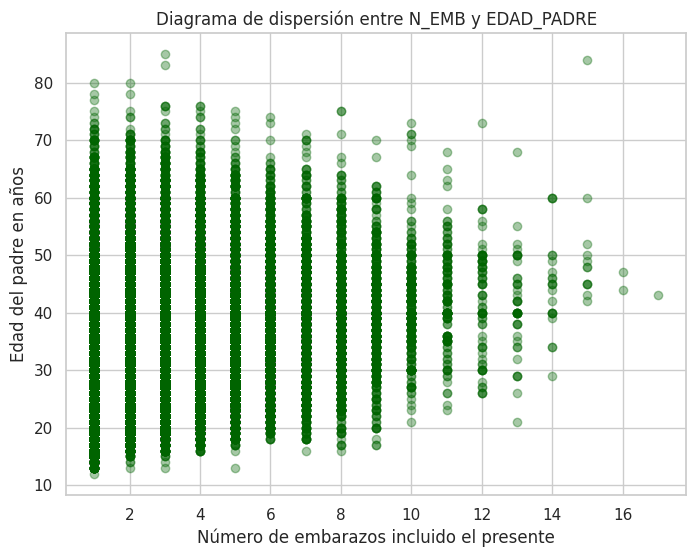

In [109]:
# =====================================================
# 3. DIAGRAMA DE DISPERSIÓN
# =====================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df_bivariado[columna_x],
    df_bivariado[columna_y],
    color="darkgreen",
    marker="o",
    alpha=0.35
)

plt.xlabel("Número de embarazos incluido el presente")
plt.ylabel("Edad del padre en años")
plt.title(
    "Diagrama de dispersión entre N_EMB y EDAD_PADRE"
)

plt.show()

Se construye el diagrama de dispersión para observar visualmente la relación entre N_EMB y EDAD_PADRE.

In [68]:
# =====================================================
# 4. PREPARAR LOS DATOS PARA LA REGRESIÓN
# =====================================================

X = np.array(
    df_bivariado[columna_x]
).reshape(-1, 1)

Y = np.array(
    df_bivariado[columna_y]
).reshape(-1, 1)

Se preparan las variables independiente y dependiente en formato matricial para aplicar la regresión lineal.

In [69]:
# =====================================================
# 5. REESCALAR ENTRE -1 Y 1
# =====================================================

escalador_x = MinMaxScaler(
    feature_range=(-1, 1)
)

escalador_y = MinMaxScaler(
    feature_range=(-1, 1)
)

X_escalado = escalador_x.fit_transform(X)

Y_escalado = escalador_y.fit_transform(Y)

Se reescalan ambas variables entre -1 y 1 para facilitar el ajuste del modelo de regresión.

In [96]:
# =====================================================
# 6. CREAR Y AJUSTAR EL MODELO
# =====================================================

modelo = LinearRegression()

modelo.fit(
    X_escalado,
    Y_escalado
)

LinearRegression()

Se crea y ajusta el modelo de regresión lineal utilizando los datos reescalados.

In [71]:
# =====================================================
# 7. REALIZAR LAS PREDICCIONES
# =====================================================

prediccion_escalada = modelo.predict(
    X_escalado
)

# Regresar las predicciones a la escala original
prediccion = escalador_y.inverse_transform(
    prediccion_escalada
)

Se realizan las predicciones del modelo y se convierten nuevamente a la escala original.

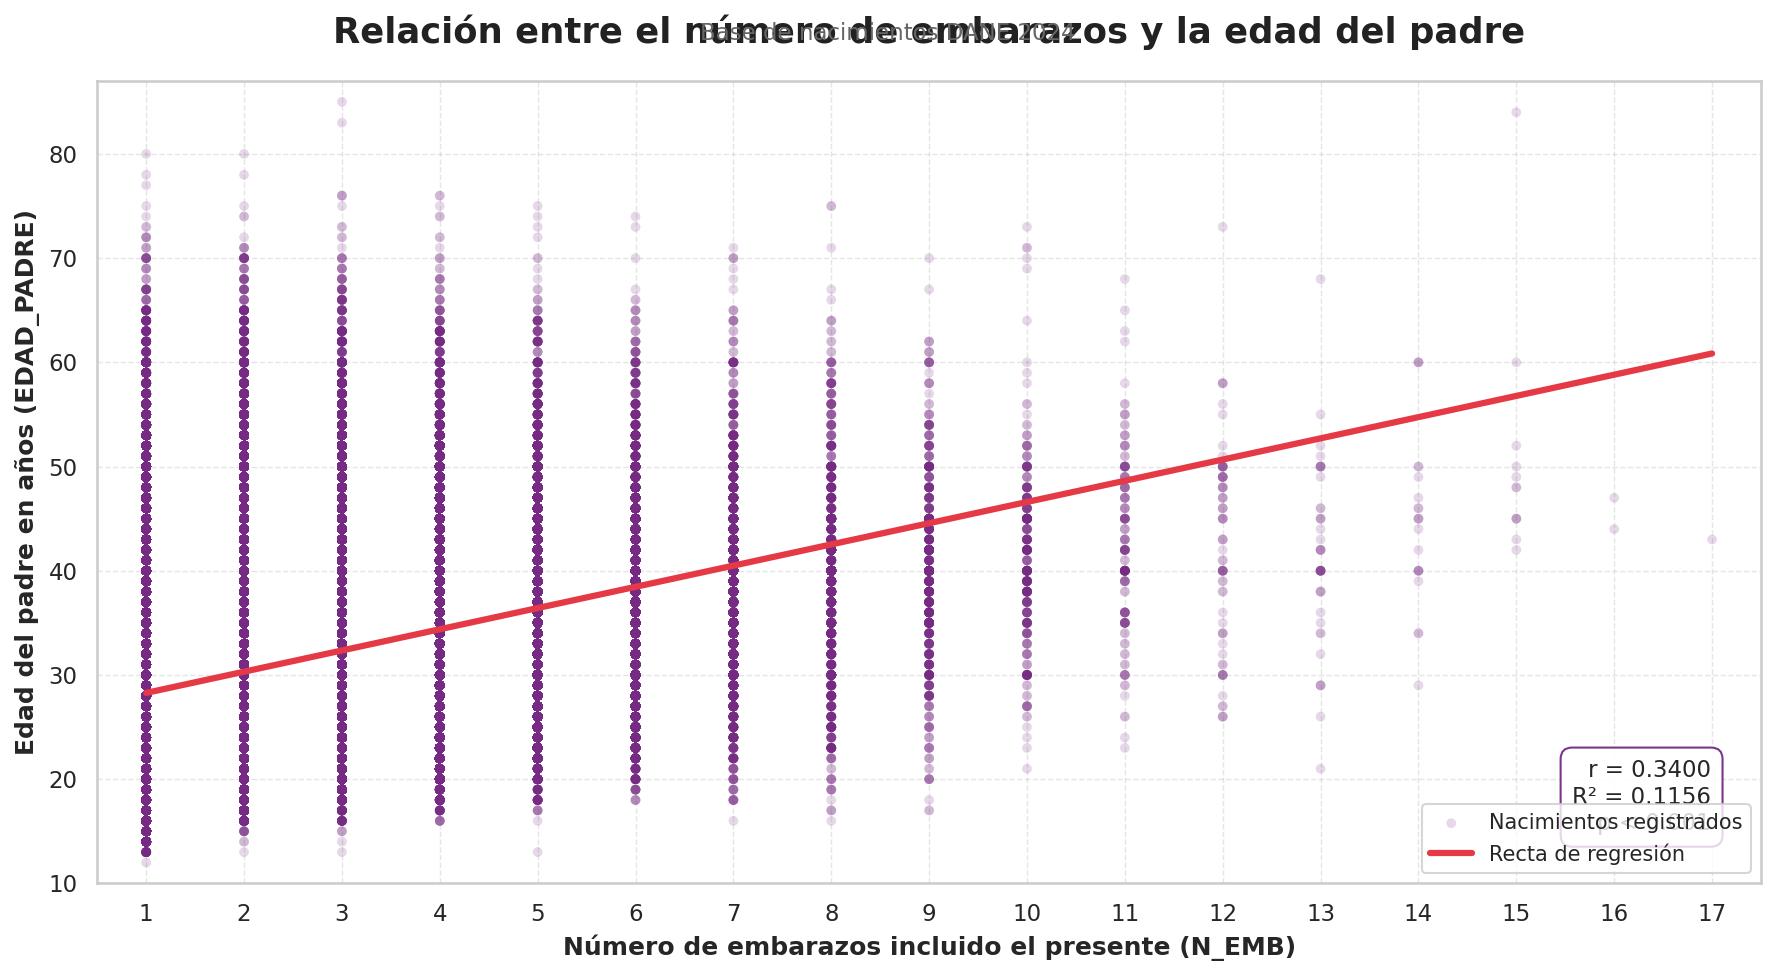

In [112]:
from scipy.stats import linregress

# Regresión lineal
regresion = linregress(
    datos["N_EMB"],
    datos["EDAD_PADRE"]
)

pendiente = regresion.slope
intercepto = regresion.intercept
r = regresion.rvalue
r2 = r**2
p_valor = regresion.pvalue

# Valores para la recta
x_recta = np.linspace(
    datos["N_EMB"].min(),
    datos["N_EMB"].max(),
    200
)

y_recta = intercepto + pendiente * x_recta

# Estilo visual
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.figure(figsize=(12, 7), dpi=150)

# Dispersión con transparencia
plt.scatter(
    datos["N_EMB"],
    datos["EDAD_PADRE"],
    s=22,
    alpha=0.18,
    color="#762A83",
    edgecolors="none",
    label="Nacimientos registrados"
)

# Recta de regresión
plt.plot(
    x_recta,
    y_recta,
    color="#E63946",
    linewidth=3,
    label="Recta de regresión"
)

# Título y etiquetas
plt.title(
    "Relación entre el número de embarazos y la edad del padre",
    fontsize=17,
    fontweight="bold",
    color="#222222",
    pad=18
)

plt.suptitle(
    "Base de nacimientos DANE 2024",
    fontsize=11,
    color="#666666",
    y=0.92
)

plt.xlabel(
    "Número de embarazos incluido el presente (N_EMB)",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Edad del padre en años (EDAD_PADRE)",
    fontsize=12,
    fontweight="bold"
)

# Texto estadístico
texto = (
    f"r = {r:.4f}\n"
    f"R² = {r2:.4f}\n"
    f"p < 0.001"
)

plt.text(
    0.97,
    0.06,
    texto,
    transform=plt.gca().transAxes,
    ha="right",
    va="bottom",
    fontsize=11,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#762A83",
        alpha=0.95
    )
)

# Límites y cuadrícula
plt.xlim(datos["N_EMB"].min() - 0.5, datos["N_EMB"].max() + 0.5)
plt.ylim(datos["EDAD_PADRE"].min() - 2, datos["EDAD_PADRE"].max() + 2)

plt.xticks(
    range(
        int(datos["N_EMB"].min()),
        int(datos["N_EMB"].max()) + 1
    )
)

plt.legend(
    loc="lower right",
    frameon=True,
    fontsize=10
)

plt.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.5
)

plt.tight_layout()




Se calcula la regresión lineal, se representa su recta sobre el diagrama de dispersión y se muestran los valores de correlación, R² y significancia estadística.

In [86]:
# =====================================================
# 9. COEFICIENTE DE PEARSON
# =====================================================

coef_pearson, valor_p_pearson = pearsonr(
    df_bivariado[columna_x],
    df_bivariado[columna_y]
)

print("Coeficiente de Pearson:", coef_pearson)
print("Valor p de Pearson:", valor_p_pearson)

Coeficiente de Pearson: 0.3400379040191515
Valor p de Pearson: 0.0


Se calcula el coeficiente de Pearson para medir la intensidad y dirección de la relación lineal entre las variables.

In [87]:
# =====================================================
# 10. COEFICIENTE DE SPEARMAN
# =====================================================

coef_spearman, valor_p_spearman = spearmanr(
    df_bivariado[columna_x],
    df_bivariado[columna_y]
)

print("Coeficiente de Spearman:", coef_spearman)
print("Valor p de Spearman:", valor_p_spearman)

Coeficiente de Spearman: 0.36717068310509177
Valor p de Spearman: 0.0


Se calcula el coeficiente de Spearman para medir la relación monotónica entre las variables mediante sus rangos.

In [95]:
# =====================================================
# 11. COEFICIENTE DE KENDALL
# =====================================================

coef_kendall, valor_p_kendall = kendalltau(
    df_bivariado[columna_x],
    df_bivariado[columna_y]
)

print("Coeficiente de Kendall:", coef_kendall)
print("Valor p de Kendall:", valor_p_kendall)

Coeficiente de Kendall: 0.28723812222507816
Valor p de Kendall: 0.0


Se calcula el coeficiente de Kendall para evaluar la concordancia y dirección de la relación entre las variables.

In [94]:
# =====================================================
# 12. MOSTRAR TODOS LOS RESULTADOS
# =====================================================

print("RESULTADOS DE CORRELACIÓN")
print("----------------------------------")

print("Coeficiente de Pearson:", coef_pearson)
print("Valor p de Pearson:", valor_p_pearson)

print()

print("Coeficiente de Spearman:", coef_spearman)
print("Valor p de Spearman:", valor_p_spearman)

print()

print("Coeficiente de Kendall:", coef_kendall)
print("Valor p de Kendall:", valor_p_kendall)

RESULTADOS DE CORRELACIÓN
----------------------------------
Coeficiente de Pearson: 0.3400379040191515
Valor p de Pearson: 0.0

Coeficiente de Spearman: 0.36717068310509177
Valor p de Spearman: 0.0

Coeficiente de Kendall: 0.28723812222507816
Valor p de Kendall: 0.0


Se muestran juntos los coeficientes y valores p de Pearson, Spearman y Kendall para compararlos.

In [99]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    palette="deep"
)

Se configura el estilo visual de los gráficos para mejorar su presentación.

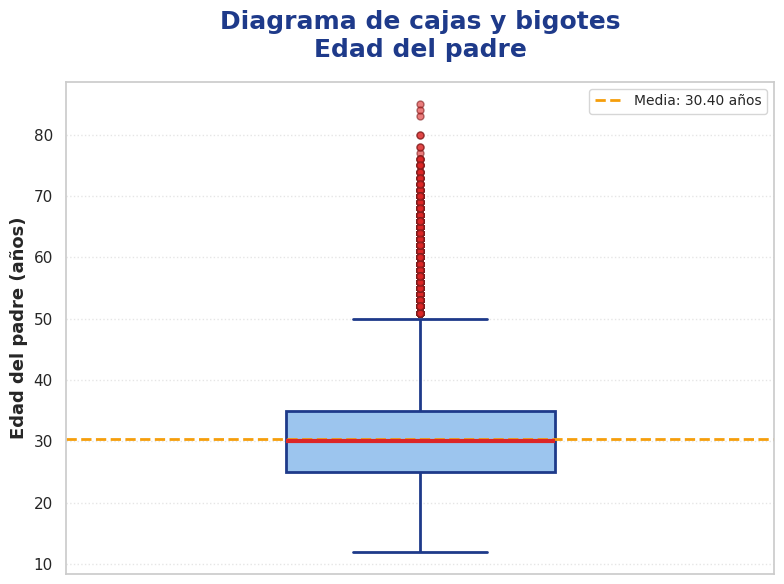

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

ax = sns.boxplot(
    y=datos['EDAD_PADRE'],
    width=0.38,
    color='#8EC5FC',
    linewidth=2.2,
    fliersize=5,
    boxprops={
        'edgecolor': '#1E3A8A',
        'linewidth': 2
    },
    whiskerprops={
        'color': '#1E3A8A',
        'linewidth': 2
    },
    capprops={
        'color': '#1E3A8A',
        'linewidth': 2
    },
    medianprops={
        'color': '#DC2626',
        'linewidth': 3
    },
    flierprops={
        'marker': 'o',
        'markerfacecolor': '#DC2626',
        'markeredgecolor': '#7F1D1D',
        'markersize': 5,
        'alpha': 0.6
    }
)

media_edad = datos['EDAD_PADRE'].mean()

plt.axhline(
    media_edad,
    color='#F59E0B',
    linestyle='--',
    linewidth=2,
    label=f'Media: {media_edad:.2f} años'
)

plt.title(
    'Diagrama de cajas y bigotes\nEdad del padre',
    fontsize=18,
    fontweight='bold',
    color='#1E3A8A',
    pad=18
)

plt.ylabel(
    'Edad del padre (años)',
    fontsize=13,
    fontweight='bold'
)

plt.xticks([])
plt.legend(
    loc='upper right',
    frameon=True,
    fontsize=10
)

plt.grid(
    axis='y',
    linestyle=':',
    alpha=0.5
)

plt.tight_layout()

plt.savefig(
    'diagrama_cajas_edad_padre.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Se construye el diagrama de cajas de EDAD_PADRE para observar su mediana, dispersión, media y posibles valores atípicos.

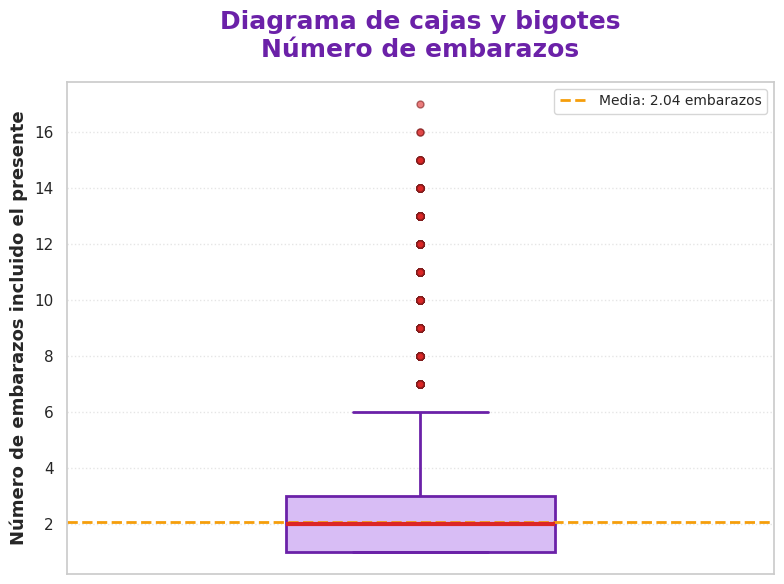

In [115]:
plt.figure(figsize=(8, 6))

ax = sns.boxplot(
    y=datos['N_EMB'],
    width=0.38,
    color='#D8B4FE',
    linewidth=2.2,
    fliersize=5,
    boxprops={
        'edgecolor': '#6B21A8',
        'linewidth': 2
    },
    whiskerprops={
        'color': '#6B21A8',
        'linewidth': 2
    },
    capprops={
        'color': '#6B21A8',
        'linewidth': 2
    },
    medianprops={
        'color': '#DC2626',
        'linewidth': 3
    },
    flierprops={
        'marker': 'o',
        'markerfacecolor': '#DC2626',
        'markeredgecolor': '#7F1D1D',
        'markersize': 5,
        'alpha': 0.6
    }
)

media_emb = datos['N_EMB'].mean()

plt.axhline(
    media_emb,
    color='#F59E0B',
    linestyle='--',
    linewidth=2,
    label=f'Media: {media_emb:.2f} embarazos'
)

plt.title(
    'Diagrama de cajas y bigotes\nNúmero de embarazos',
    fontsize=18,
    fontweight='bold',
    color='#6B21A8',
    pad=18
)

plt.ylabel(
    'Número de embarazos incluido el presente',
    fontsize=13,
    fontweight='bold'
)

plt.xticks([])
plt.legend(
    loc='upper right',
    frameon=True,
    fontsize=10
)

plt.grid(
    axis='y',
    linestyle=':',
    alpha=0.5
)

plt.tight_layout()

plt.savefig(
    'diagrama_cajas_n_emb.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


Se construye el diagrama de cajas de N_EMB para observar su mediana, dispersión, media y posibles valores atípicos.

In [116]:
from scipy import stats

Se importa SciPy para aplicar pruebas estadísticas como Shapiro-Wilk.

In [117]:
# =====================================================
# PRUEBA DE NORMALIDAD DE SHAPIRO-WILK
# =====================================================

# Se toma una muestra de máximo 5.000 datos
muestra_edad = datos["EDAD_PADRE"].sample(
    n=min(5000, len(datos)),
    random_state=42
)

muestra_emb = datos["N_EMB"].sample(
    n=min(5000, len(datos)),
    random_state=42
)

# Aplicar la prueba de Shapiro-Wilk
shapiro_edad = stats.shapiro(muestra_edad)
shapiro_emb = stats.shapiro(muestra_emb)

# Mostrar resultados
print("SHAPIRO-WILK: EDAD_PADRE")
print("Estadístico W:", round(shapiro_edad.statistic, 4))
print("Valor p:", shapiro_edad.pvalue)

print("\nSHAPIRO-WILK: N_EMB")
print("Estadístico W:", round(shapiro_emb.statistic, 4))
print("Valor p:", shapiro_emb.pvalue)

# La prueba de Shapiro-Wilk se aplicó sobre una muestra aleatoria de 5.000 observaciones de cada variable. En ambos casos, el valor p es menor que 0,05; por tanto, se rechaza la hipótesis nula de normalidad. En consecuencia, EDAD_PADRE y N_EMB no siguen una distribución normal.


SHAPIRO-WILK: EDAD_PADRE
Estadístico W: 0.9668
Valor p: 1.829947379271494e-32

SHAPIRO-WILK: N_EMB
Estadístico W: 0.7654
Valor p: 1.2279412020385126e-64


La prueba de Shapiro-Wilk indica que EDAD_PADRE y N_EMB no siguen una distribución normal porque sus valores p son menores que 0,05.

In [118]:
# =====================================================
# REGRESIÓN LINEAL
# =====================================================

from scipy.stats import linregress

# X: variable independiente
# Y: variable dependiente
regresion = linregress(
    datos["N_EMB"],
    datos["EDAD_PADRE"]
)

# Extraer resultados
pendiente = regresion.slope
intercepto = regresion.intercept
r = regresion.rvalue
r2 = r**2
valor_p = regresion.pvalue

# Mostrar resultados
print("RESULTADOS DE LA REGRESIÓN LINEAL")
print("----------------------------------")
print(f"Pendiente: {pendiente:.6f}")
print(f"Intercepto: {intercepto:.6f}")
print(f"Coeficiente de Pearson: {r:.6f}")
print(f"Coeficiente de determinación R²: {r2:.6f}")
print(f"Valor p: {valor_p:.10f}")

print("\nEcuación de la recta:")
print(
    f"EDAD_PADRE estimada = "
    f"{intercepto:.6f} + "
    f"{pendiente:.6f} * N_EMB"
)

RESULTADOS DE LA REGRESIÓN LINEAL
----------------------------------
Pendiente: 2.035757
Intercepto: 26.243429
Coeficiente de Pearson: 0.340038
Coeficiente de determinación R²: 0.115626
Valor p: 0.0000000000

Ecuación de la recta:
EDAD_PADRE estimada = 26.243429 + 2.035757 * N_EMB


Se calcula la regresión lineal para obtener la pendiente, el intercepto, el coeficiente de Pearson y el valor de R².